<a href="https://colab.research.google.com/github/dmi3eva/marlo/blob/main/edu/stag_hunt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import numpy as np
from typing import *
rng = np.random.default_rng()

# Игра

In [2]:
a = 2 # больший выигрыш, глобальный оптимум (олень)
b = 0 # большая доля от зайца
c = 0  # меньшая доля от зайца
d = 1 # меньший выигрыш, неглобальный оптимум (заяц)
STAG_HUNT = np.array([[(a, a), (b, c)], [(c, b), (d, d)]])

In [3]:
class GameStagHunt():
  def __init__(self, reward_matrix: Optional[np.array]=STAG_HUNT):
    self.reward_matrix = reward_matrix
    self.n_agents = reward_matrix.shape[-1]
    self.n_actions = reward_matrix.shape[0]

  def reward(self, actions: List[int]) -> int:
    rewards = self.reward_matrix[*actions]
    total = sum(rewards)
    return total

  def joint_actions(self) -> np.array:
    grid = np.indices((self.n_actions,) * 2).reshape(2, -1).T
    return grid

In [4]:
game = GameStagHunt()
game.reward((0, 0))

np.int64(4)

# Политики

In [10]:
class IndependentDiscretePolicy():

  def __init__(self, actions: tuple[int]):
    self.actions: list[int] = list(actions)

  def actions(self):
    probas = {
        (0, 0): 0.,
        (0, 1): 0.,
        (1, 0): 0.,
        (1, 1): 0.
    }
    tupled = tuple(self.actions)
    probas[tupled] = 1.
    return probas

  def get_action(self, agent_id: int) -> int:
    return self.actions[agent_id]

  def set_action(self, agent_id: int, action_id: int) -> NoReturn:
    self.actions[agent_id] = action_id

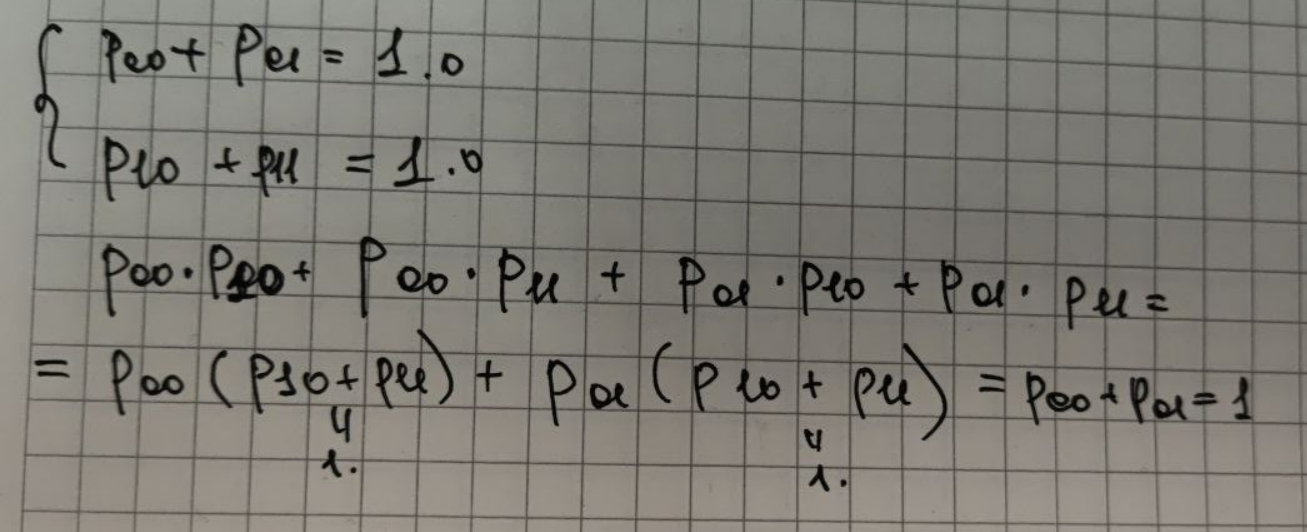

In [13]:
class IndependentStoсhasticPolicy():

  def __init__(self, actions: List[Dict[int, float]]):
    self.actions = actions

  def actions(self):
    probas = {
        (0, 0): self.actions[0][0] * self.actions[1][0],
        (0, 1): self.actions[0][0] * self.actions[1][1],
        (1, 0): self.actions[0][1] * self.actions[1][0],
        (1, 1): self.actions[0][1] * self.actions[1][1],
    }
    return probas

  def get_action(self, agent_id: int) -> int:
    options = list(self.actions[agent_id].keys())
    probas = [self.actions[agent_id][k] for k in options]
    sample = rng.choice(options, p=probas)
    return sample

  def set_action(self, agent_id: int, action_id: int, proba: float) -> NoReturn:
    self.actions[agent_id][action_id] = proba

In [14]:
# Action-Dependent Policy

class ADGPolicy():

  def init(self):
    pass

  def get_action(self, agent_id: int) -> int:
    raise NotImplementedError

  def set_action(self, agent_id: int, action_id: int) -> NoReturn:
    raise NotImplementedError

In [5]:
game.joint_actions()

array([[0, 0],
       [0, 1],
       [1, 0],
       [1, 1]])